# 01 · Exploración de datos (EDA) y preprocesamiento
**Equipo 4 · Bank Marketing Dataset (UCI)**

## 1. Descripción del problema
Un banco realiza campañas telefónicas para ofrecer un depósito a plazo. Queremos entender qué
clientes aceptan (`y = yes`) y qué características del cliente y de la campaña se relacionan con ello.

**Preguntas del EDA**
1. ¿Qué tan desbalanceada está la variable objetivo?
2. ¿Qué variables numéricas y categóricas se relacionan con la aceptación?
3. ¿Cómo influyen las campañas de contacto y las variables temporales (mes, día)?
4. ¿Qué problemas de calidad hay (`unknown`, `pdays = -1`, colas largas, duplicados)?

> **Importante:** el EDA se hace solo con el conjunto de **entrenamiento** para que las decisiones
> de preprocesamiento no usen información del conjunto de prueba.

In [1]:
import sys
sys.path.append("..")   # permite `from src import ...` al ejecutar desde notebooks/

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src import config
from src.data_loader import get_train_test, load_data

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)
config.RESULTS_DIR.mkdir(parents=True, exist_ok=True)

X_train, X_test, y_train, y_test = get_train_test()
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (36168, 15) | Test: (9043, 15)


## 2. Comprensión de los datos

In [2]:
df = X_train.assign(y=y_train)
display(df.head())
print(df.dtypes)
print("\nValores nulos por columna:\n", df.isna().sum()[df.isna().sum() > 0])
print("Filas duplicadas:", df.duplicated().sum())

,age,job,marital,education,default,balance,housing,loan,contact,day,month,campaign,pdays,previous,poutcome,y
24001,36,technician,divorced,secondary,no,861,no,no,telephone,29,aug,2,-1,0,unknown,0
43409,24,student,single,secondary,no,4126,no,no,cellular,5,apr,4,185,7,failure,1
20669,44,technician,single,secondary,no,244,yes,no,cellular,12,aug,4,-1,0,unknown,1
18810,48,unemployed,married,secondary,no,0,no,no,telephone,31,jul,11,-1,0,unknown,0
23130,38,technician,married,secondary,no,257,no,no,cellular,26,aug,10,-1,0,unknown,0


age          int64
job            str
marital        str
education      str
default        str
balance      int64
housing        str
loan           str
contact        str
day          int64
month          str
campaign     int64
pdays        int64
previous     int64
poutcome       str
y            int64
dtype: object

Valores nulos por columna:
 Series([], dtype: int64)
Filas duplicadas: 10


In [3]:
# 'unknown' es un valor faltante disfrazado en las categóricas
cat_cols = X_train.select_dtypes(exclude=np.number).columns.tolist()
num_cols = X_train.select_dtypes(include=np.number).columns.tolist()
unknown = (X_train[cat_cols] == "unknown").mean().sort_values(ascending=False)
display((unknown[unknown > 0] * 100).round(1).to_frame("% unknown"))

,% unknown
poutcome,81.8
contact,28.7
education,4.1
job,0.6


**Hallazgos:**
- **Tamaño, tipos y calidad:** el conjunto de entrenamiento tiene 36.168 clientes y 15 variables (6 numéricas y 9 categóricas; `duration` ya viene excluida). No hay valores nulos explícitos y solo hay 10 filas duplicadas (0,03 %). Como no existe un identificador de cliente, pueden ser personas distintas con el mismo perfil, así que se conservan.
- **`unknown`** es el faltante disfrazado: `poutcome` (81,8 %), `contact` (28,7 %), `education` (4,1 %) y `job` (0,6 %). En `poutcome` casi siempre significa "no hubo campaña anterior" (no es un dato perdido sino "no aplica"), y en `contact` se asocia a una aceptación de solo 4,1 %, es decir, es informativo. Decisión: conservar `unknown` como categoría propia en lugar de imputarlo o borrar filas.

## 3. Variable objetivo y desbalance

y
no     31937
yes     4231
Name: count, dtype: int64 
 y
no     0.883
yes    0.117
Name: count, dtype: float64


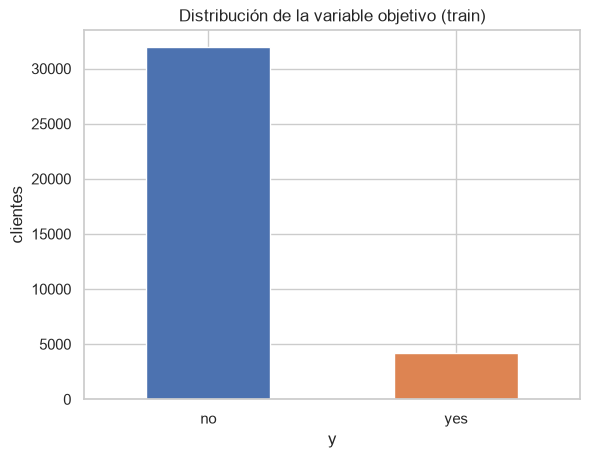

In [4]:
conteo = y_train.value_counts().rename({0: "no", 1: "yes"})
print(conteo, "\n", (conteo / conteo.sum()).round(3))
ax = conteo.plot(kind="bar", color=["#4C72B0", "#DD8452"], rot=0)
ax.set_title("Distribución de la variable objetivo (train)"); ax.set_ylabel("clientes")
plt.savefig(config.FIGURES_DIR / "eda_objetivo.png", dpi=150, bbox_inches="tight"); plt.show()

**Hallazgos:** solo el **11,7 %** de los clientes acepta (4.231 "yes" frente a 31.937 "no", unos 7,5 "no" por cada "yes"). Un modelo que siempre prediga "no" tendría un 88,3 % de *accuracy* sin encontrar a ningún cliente interesado, por eso la *accuracy* no sirve como única métrica. Estrategias: partición estratificada (ya aplicada), pesos de clase (`class_weight="balanced"`) y evaluación con **F1, Recall y Precision de la clase "yes"**, **ROC-AUC** y sobre todo **PR-AUC**, que es la más sensible al desbalance. También conviene ajustar el umbral de decisión en lugar de usar 0,5 por defecto.

## 4. Variables numéricas

,count,mean,std,min,25%,50%,75%,max
age,36168.0,40.89,10.63,18.0,33.0,39.0,48.00,95.0
balance,36168.0,1365.49,3068.54,-8019.0,74.0,451.0,1430.25,102127.0
day,36168.0,15.82,8.33,1.0,8.0,16.0,21.00,31.0
campaign,36168.0,2.76,3.10,1.0,1.0,2.0,3.00,63.0
pdays,36168.0,40.16,100.16,-1.0,-1.0,-1.0,-1.00,871.0
previous,36168.0,0.58,2.41,0.0,0.0,0.0,0.00,275.0


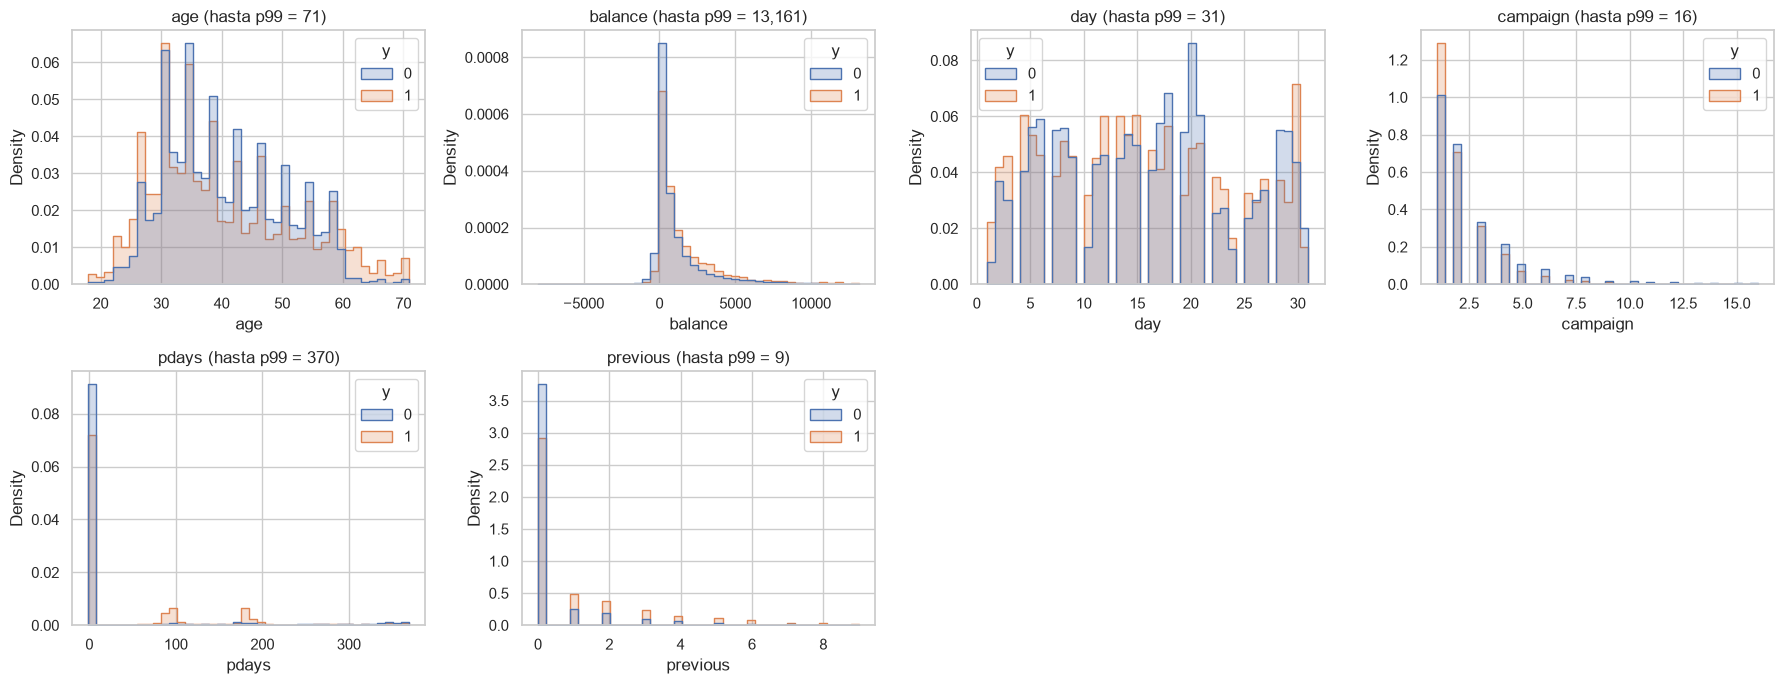

In [5]:
display(X_train[num_cols].describe().T.round(2))
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, col in zip(axes.ravel(), num_cols):
    p99 = df[col].quantile(0.99)   # solo para graficar: los extremos aplastan la distribución
    sns.histplot(data=df[df[col] <= p99], x=col, hue="y", bins=40, ax=ax, element="step", stat="density", common_norm=False)
    ax.set_title(f"{col} (hasta p99 = {p99:,.0f})")
for ax in axes.ravel()[len(num_cols):]:
    ax.axis("off")
plt.tight_layout(); plt.savefig(config.FIGURES_DIR / "eda_numericas.png", dpi=150); plt.show()

In [6]:
# Valores atípicos (regla del rango intercuartílico)
q1, q3 = X_train[num_cols].quantile(0.25), X_train[num_cols].quantile(0.75)
iqr = q3 - q1
outliers = ((X_train[num_cols] < q1 - 1.5 * iqr) | (X_train[num_cols] > q3 + 1.5 * iqr)).mean()
display((outliers.sort_values(ascending=False) * 100).round(1).to_frame("% atípicos"))

,% atípicos
pdays,18.2
previous,18.2
balance,10.4
campaign,6.8
age,1.1
day,0.0


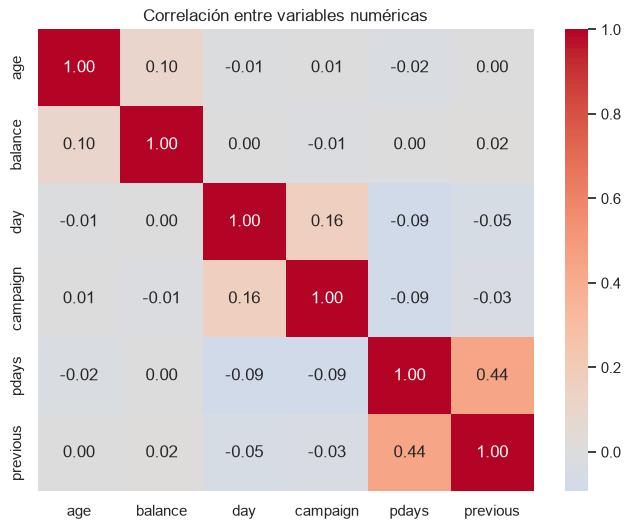

In [7]:
plt.figure(figsize=(8, 6))
sns.heatmap(X_train[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlación entre variables numéricas")
plt.savefig(config.FIGURES_DIR / "eda_correlacion.png", dpi=150, bbox_inches="tight"); plt.show()

**Hallazgos:**
- **Asimetría:** `balance` (asimetría 8,3; de -8.019 a 102.127), `campaign` (4,9; máximo 63) y `previous` (45; máximo 275) tienen colas derechas muy largas. Esto justifica el **log con signo**, que comprime la cola y conserva los saldos negativos.
- **Atípicos:** `pdays` y `previous` marcan un 18,2 % de atípicos por la regla IQR, pero no son errores: el 81,8 % nunca fue contactado (`pdays = -1`, `previous = 0`), así que cualquier contacto previo queda fuera del rango. Por eso `pdays` se convierte en bandera + NaN en vez de recortarse. Los de `balance` (10,4 %) y `campaign` (6,8 %) son valores reales posibles: no se eliminan, se suavizan con el log.
- **Edad:** la aceptación tiene forma de U: 24,4 % en menores de 26 años y 42,1 % en mayores de 60, frente a un 9-10 % entre 30 y 60. Es una relación no lineal que los modelos lineales no captan directamente.
- **Correlaciones:** son bajas en general. La única relevante es `pdays`–`previous` (0,44), porque ambas describen el historial de contactos. No hay multicolinealidad fuerte que obligue a eliminar variables numéricas.
- **Escalas:** son muy distintas (edad en decenas, saldo en miles), por lo que se aplica `StandardScaler`, necesario para la regresión logística, KNN y K-Means.

## 5. Variables categóricas (tasa de aceptación por categoría)

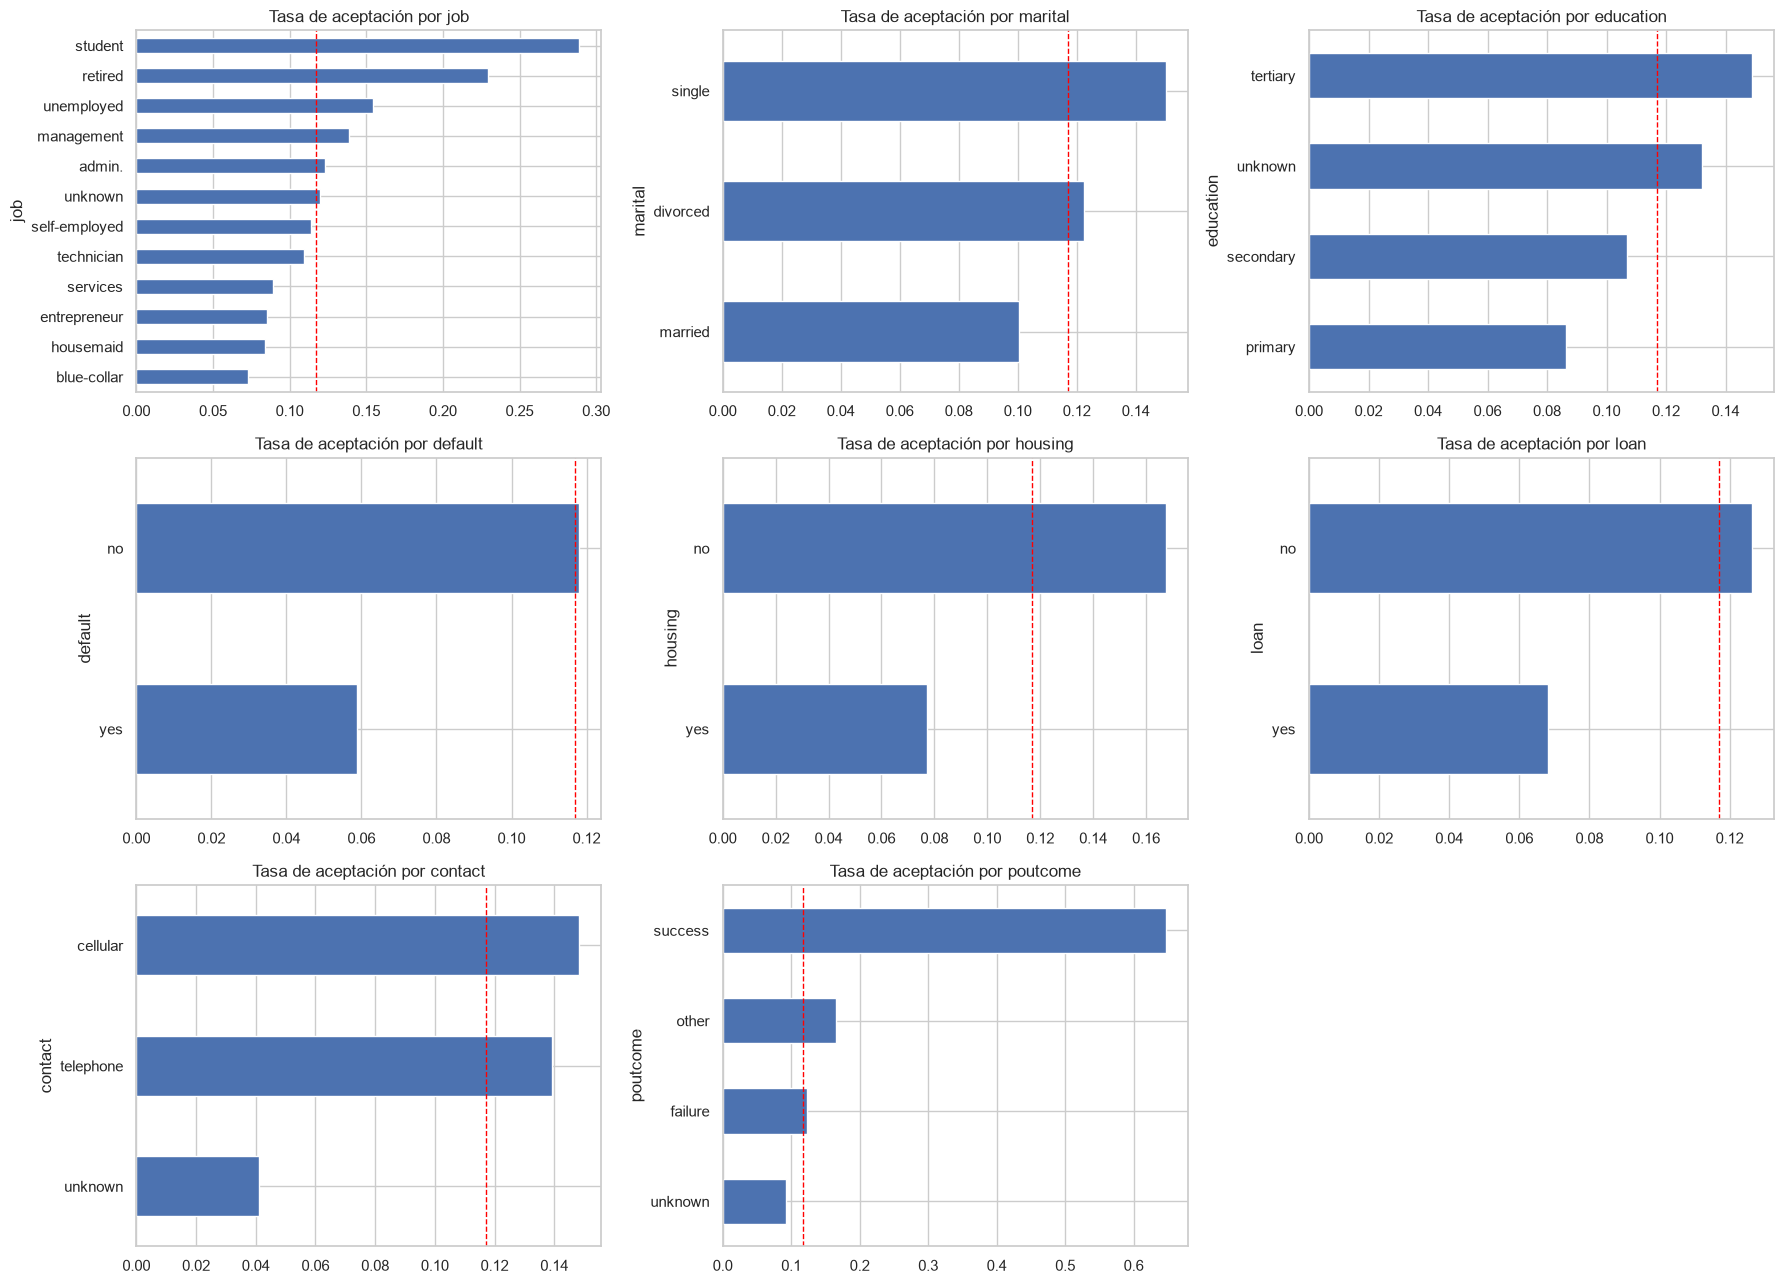

In [8]:
fig, axes = plt.subplots(3, 3, figsize=(18, 13))
for ax, col in zip(axes.ravel(), [c for c in cat_cols if c != "month"]):
    rate = df.groupby(col)["y"].mean().sort_values()
    rate.plot(kind="barh", ax=ax, color="#4C72B0")
    ax.axvline(df["y"].mean(), color="red", ls="--", lw=1)
    ax.set_title(f"Tasa de aceptación por {col}"); ax.set_xlabel("")
for ax in axes.ravel()[len(cat_cols) - 1:]:
    ax.axis("off")
plt.tight_layout(); plt.savefig(config.FIGURES_DIR / "eda_categoricas.png", dpi=150); plt.show()

**Hallazgos** (promedio = 11,7 %, línea roja):
- **Por encima:** `job` = student (28,9 %) y retired (23,0 %), coherente con la U de la edad; unemployed (15,4 %) y management (13,9 %). `housing` = no (16,7 % frente a 7,7 % con hipoteca), `marital` = single (15,0 %), `education` = tertiary (14,9 %) y `contact` = cellular (14,8 %).
- **Por debajo:** `contact` = unknown (4,1 %), `default` = yes (5,9 %, solo el 1,8 % de los clientes), `loan` = yes (6,8 %), `job` = blue-collar (7,3 %), housemaid (8,4 %) y entrepreneur (8,5 %), y `education` = primary (8,6 %).
- **Lectura:** aceptan más los clientes con menos compromisos financieros (sin hipoteca, sin préstamo personal, sin mora) y los de los extremos de edad (estudiantes y jubilados).

## 6. Campañas de contacto y variables temporales

In [9]:
df["previously_contacted"] = (df["pdays"] != -1)
print("Clientes contactados antes:", f"{df['previously_contacted'].mean():.1%}")
display(df.groupby("previously_contacted")["y"].agg(clientes="size", tasa_aceptacion="mean"))
display(df.groupby("poutcome")["y"].agg(clientes="size", tasa_aceptacion="mean"))

df["campaign_bin"] = pd.cut(df["campaign"], [0, 1, 2, 3, 5, 10, 100], labels=["1", "2", "3", "4-5", "6-10", ">10"])
display(df.groupby("campaign_bin", observed=True)["y"].agg(clientes="size", tasa_aceptacion="mean"))

Clientes contactados antes: 18.2%


,clientes,tasa_aceptacion
previously_contacted,,
False,29584,0.092178
True,6584,0.228433


,clientes,tasa_aceptacion
poutcome,,
failure,3889,0.122911
other,1485,0.164983
success,1205,0.646473
unknown,29589,0.092230


,clientes,tasa_aceptacion
campaign_bin,,
1,14026,0.145872
2,10023,0.111543
3,4412,0.112647
4-5,4224,0.086648
6-10,2538,0.065012
>10,945,0.041270


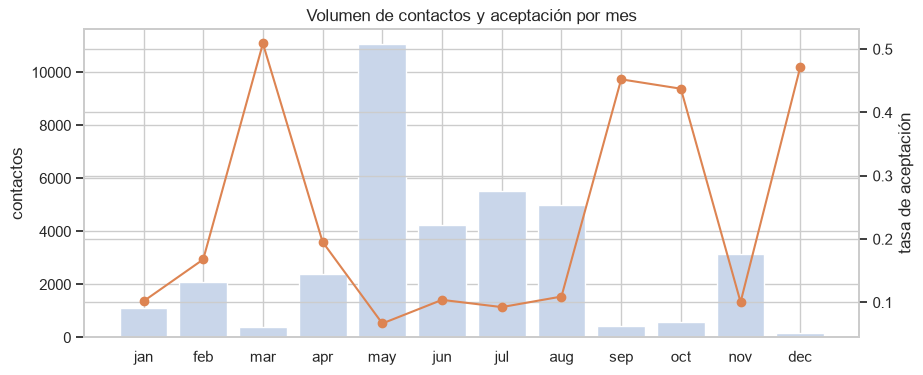

In [10]:
order = ["jan", "feb", "mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]
by_month = df.groupby("month")["y"].agg(clientes="size", tasa="mean").reindex(order)
fig, ax1 = plt.subplots(figsize=(10, 4))
ax1.bar(by_month.index, by_month["clientes"], color="#C9D6EA"); ax1.set_ylabel("contactos")
ax2 = ax1.twinx(); ax2.plot(by_month.index, by_month["tasa"], color="#DD8452", marker="o"); ax2.set_ylabel("tasa de aceptación")
plt.title("Volumen de contactos y aceptación por mes")
plt.savefig(config.FIGURES_DIR / "eda_mes.png", dpi=150, bbox_inches="tight"); plt.show()

In [11]:
# Justificación de excluir 'duration': solo se conoce tras terminar la llamada
raw = load_data()
display(raw.groupby("y")["duration"].describe().round(1))

,count,mean,std,min,25%,50%,75%,max
y,,,,,,,,
no,39922.0,221.2,207.4,0.0,95.0,164.0,279.0,4918.0
yes,5289.0,537.3,392.5,8.0,244.0,426.0,725.0,3881.0


**Hallazgos:**
- **Contactos previos:** solo el 18,2 % había sido contactado antes, pero ese grupo acepta un 22,8 % frente al 9,2 % de los nuevos. `poutcome = success` alcanza un **64,6 %** de aceptación (1.205 clientes) y es el indicador individual más fuerte; `failure` queda en 12,3 %.
- **Número de contactos en la campaña:** la tasa baja de forma constante: 14,6 % con 1 llamada, ~11 % con 2-3, 8,7 % con 4-5, 6,5 % con 6-10 y 4,1 % con más de 10. Insistir demasiado no mejora la conversión y desgasta al cliente.
- **Estacionalidad:** mayo concentra el 30,6 % de los contactos (11.062) y tiene la tasa más baja (6,7 %). Marzo (50,9 %), diciembre (47,2 %), septiembre (45,2 %) y octubre (43,8 %) superan el 40 %, pero con muy pocas llamadas (178-592). El mes importa mucho; parte del efecto puede deberse a que en los meses de poco volumen se llamó a clientes más seleccionados. Se codifica con seno/coseno para respetar que diciembre y enero son meses contiguos.
- **`duration`:** quienes aceptan hablan en promedio 537 s frente a 221 s (medianas de 426 y 164 s). Parece muy predictiva, pero solo se conoce **cuando la llamada termina** (y una duración de 0 implica un "no" seguro). Usarla sería fuga de información: el modelo debe servir para decidir a quién llamar **antes** de llamar, así que se excluye.

## 7. Preprocesamiento
Pipeline definido en `src/preprocessing.py` (se ajusta solo con entrenamiento):

| Paso | Decisión | Justificación |
|---|---|---|
| `pdays = -1` | Bandera `previously_contacted` y `pdays` → NaN | -1 no es una distancia real |
| `balance`, `campaign`, `previous` | Log con signo | Colas largas |
| `month` | Seno/coseno del mes | Variable cíclica |
| Numéricas | Mediana + `StandardScaler` | Robustez a nulos y escala comparable |
| Categóricas | `unknown` como categoría + One-Hot | `unknown` puede ser informativo |
| `duration` | Excluida | Fuga de información |

In [12]:
from src.preprocessing import build_preprocessor, get_feature_names

prep = build_preprocessor().fit(X_train)          # fit SOLO con train
Xt_train, Xt_test = prep.transform(X_train), prep.transform(X_test)
print("Matriz train:", Xt_train.shape, "| test:", Xt_test.shape)
print("NaN restantes:", np.isnan(Xt_train).sum())
print("Primeras columnas:", get_feature_names(prep)[:12])

Matriz train: (36168, 41) | test: (9043, 41)
NaN restantes: 0
Primeras columnas: ['age', 'balance', 'day', 'campaign', 'pdays', 'previous', 'previously_contacted', 'month_sin', 'month_cos', 'job_admin.', 'job_blue-collar', 'job_entrepreneur']


**Decisiones y limitaciones:**
- El pipeline produce 41 columnas sin NaN; se ajusta solo con entrenamiento y se aplica igual a prueba, por lo que no hay fuga de información.
- **Alternativas que probaríamos:** (1) agrupar categorías de `job` con tasas parecidas (housemaid, entrepreneur y services, entre 8 y 9 %); (2) tramos de edad o un término cuadrático para capturar la U; (3) `OneHotEncoder(drop="if_binary")` para no duplicar binarias como `housing_yes`/`housing_no`; (4) eliminar las dummies con información mutua ≈ 0 (sección 8).
- **Riesgo de tratar `unknown` como categoría:** mezcla significados distintos. En `poutcome` significa "no aplica" y repite la información de `previously_contacted`. En `contact` es un problema de registro: el 58 % de los contactos de mayo y el 85 % de los de junio tienen `contact = unknown`, frente a casi 0 % en el resto de meses. Así, su baja aceptación (4,1 %) puede reflejar la época de la campaña y no el canal, y el modelo podría aprender un artefacto del proceso de captura que no se repita con datos nuevos.

## 8. Selección de variables y reducción de dimensionalidad (exploratoria)
Antes de modelar, medimos **qué variables aportan información sobre `y`** (información mutua, calculada solo
con entrenamiento) y **cuánta redundancia hay** (varianza acumulada de PCA). La comparación formal de estrategias
de selección con modelos está en `02_supervisado.ipynb`.

,info_mutua
poutcome_success,0.0277
pdays,0.0251
month_cos,0.0221
balance,0.0199
month_sin,0.0170
poutcome_unknown,0.0170
contact_unknown,0.0151
contact_cellular,0.0150
housing_no,0.0144
previous,0.0133


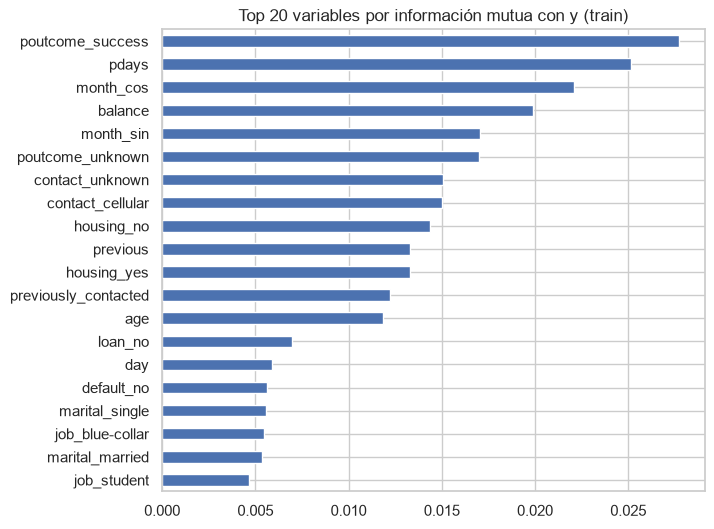

Variables con información mutua ≈ 0 (<0.001): 10 de 41


In [13]:
from sklearn.feature_selection import mutual_info_classif
from sklearn.decomposition import PCA

names = get_feature_names(prep)
mi = pd.Series(mutual_info_classif(Xt_train, y_train, random_state=config.RANDOM_STATE), index=names)
mi = mi.sort_values(ascending=False)
display(mi.head(15).round(4).to_frame("info_mutua"))

plt.figure(figsize=(7, 6)); mi.head(20)[::-1].plot(kind="barh", color="#4C72B0")
plt.title("Top 20 variables por información mutua con y (train)")
plt.savefig(config.FIGURES_DIR / "eda_info_mutua.png", dpi=150, bbox_inches="tight"); plt.show()
print("Variables con información mutua ≈ 0 (<0.001):", int((mi < 0.001).sum()), "de", len(mi))

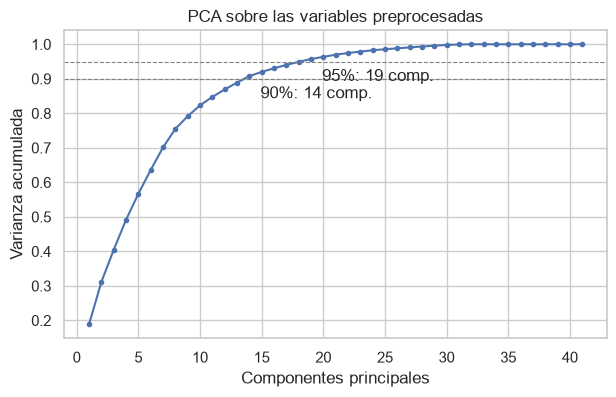

41 variables tras el preprocesamiento → 19 componentes explican el 95 % de la varianza


In [14]:
pca_full = PCA(random_state=config.RANDOM_STATE).fit(Xt_train)
cum = np.cumsum(pca_full.explained_variance_ratio_)
plt.figure(figsize=(7, 4)); plt.plot(range(1, len(cum) + 1), cum, marker="o", ms=3)
for thr in (0.90, 0.95):
    k = int(np.argmax(cum >= thr)) + 1
    plt.axhline(thr, ls="--", color="gray", lw=0.8); plt.annotate(f"{thr:.0%}: {k} comp.", (k, thr), textcoords="offset points", xytext=(8, -14))
plt.xlabel("Componentes principales"); plt.ylabel("Varianza acumulada"); plt.title("PCA sobre las variables preprocesadas")
plt.savefig(config.FIGURES_DIR / "eda_pca_varianza.png", dpi=150, bbox_inches="tight"); plt.show()
print(f"{Xt_train.shape[1]} variables tras el preprocesamiento → {int(np.argmax(cum >= 0.95)) + 1} componentes explican el 95 % de la varianza")

**Hallazgos:**
- **Más informativas:** `poutcome_success` (0,028), `pdays` (0,025), el mes (`month_cos` 0,022 y `month_sin` 0,017), `balance` (0,020), `contact` unknown/cellular (0,015), `housing` (0,014), `previous` (0,013), `previously_contacted` (0,012) y `age` (0,012). Coinciden con el EDA: historial de contactos, mes, canal y compromisos financieros. Los valores son bajos: ninguna variable sola explica la aceptación, hace falta combinarlas.
- **Prácticamente irrelevantes (< 0,001):** 10 de 41: `job_management`, `job_services`, `job_technician`, `job_unemployed`, `job_entrepreneur`, `job_unknown`, `marital_divorced`, `poutcome_other`, `education_primary` y `default_yes`. Son candidatas a eliminar, con cuidado: la información mutua es univariada y mide cada dummy por separado. La variable `job` en conjunto sí aporta (student y retired), y `default_yes` es rara pero tiene una tasa muy baja.
- **Redundancia (PCA):** 14 componentes explican el 90 % de la varianza y 19 el 95 %, de 41 columnas. Hay redundancia por las dummies complementarias (`housing_yes`/`housing_no`, `loan_yes`/`loan_no`, `poutcome_unknown` ≈ `previously_contacted`) y por `pdays`–`previous`. Aun así, los dos primeros componentes solo explican el 31,1 %: la información no se concentra en pocas dimensiones, por lo que una proyección 2D sirve para visualizar, pero pierde mucho.
- **Recomendación para el componente supervisado:** comparar con validación cruzada (PR-AUC y F1) (a) todas las variables, (b) `SelectKBest` por información mutua con k = 20 y (c) PCA al 95 % (~19 componentes). Esperamos que la selección por información mutua mantenga el rendimiento con la mitad de las variables y siga siendo interpretable, mientras que PCA reduce dimensiones sin una ganancia clara y pierde interpretabilidad.